# 05 · Choosing a limb-darkening law

**Level:** intermediate · **Prerequisites:** [01](01_first_light_curve.ipynb), [03](03_first_fit.ipynb) · **Run time:** ~1–2 min

**Covers:** the six laws plus logarithmic and power-2 with free α, `MarginalTransitModel.fit()` with each law, comparing geometry, intensity profiles and residuals, the pitfalls of a wrong law

A real star does not come with a label saying which law to use. We fit the **same light curve with every law**
and compare the answers. The fits use `MarginalTransitModel.fit()`, which integrates the limb-darkening coefficients out
(it is explained in detail in [notebook 06](06_marginal_transit_model.ipynb); here we only use it).

By the end you will know

1. what a limb-darkening *law* is, and what the planet's transit tells us about it;
2. how to run `fit()` with any law (a one-line change) and how to read its diagnostics;
3. how to compare laws: the geometry (R<sub>p</sub>/R<sub>⋆</sub>, a/R<sub>⋆</sub>, b), the limb-darkening profile itself, and the residuals;
4. the main pitfalls (for example: a wrong law can give a *confidently wrong* answer).

Requirements: `pizzetti[fit]` (adds `emcee` and `scipy`), `matplotlib`, and `batman-package` (only used in the last section
to draw model light curves).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import batman
import pizzetti

print("pizzetti", pizzetti.__version__, "| batman", batman.__version__)

# Plot style: quiet greys for text and grid, one fixed colour per law (same colour in every figure).
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1.0,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2.0,
    "lines.solid_capstyle": "round", "legend.frameon": False, "font.size": 10,
})

pizzetti 0.3.0 | batman 2.5.1


## 1. What is a limb-darkening law?

A star looks darker towards its edge, the **limb**. Let *r* be the distance from the centre of the stellar disk, in units of
the stellar radius (*r* = 0 at the centre, *r* = 1 at the limb), and define

$$ \mu = \cos\theta = \sqrt{1 - r^2}, $$

where θ is the angle between our line of sight and the local vertical of the star's surface. At the centre μ = 1: we look straight down
into the star and see deep, hot gas. Near the limb μ → 0: we look through the star's atmosphere at a grazing angle and see only
higher, cooler, dimmer gas.

A **limb-darkening law** is a formula for the intensity profile *I*(μ), normalised so that *I*(1) = 1, with a few free
**coefficients**. pizzetti knows these laws (the same names and conventions as batman):

| `limb_dark` | *I*(μ) / *I*(1) | coefficients |
|---|---|---|
| `"uniform"` | 1 | none (no limb darkening) |
| `"linear"` | 1 − u₁ (1−μ) | 1 |
| `"quadratic"` | 1 − u₁ (1−μ) − u₂ (1−μ)² | 2 |
| `"squareroot"` | 1 − u₁ (1−μ) − u₂ (1−√μ) | 2 |
| `"logarithmic"` | 1 − u₁ (1−μ) − u₂ μ ln μ | 2 |
| `"power2"` | 1 − c (1−μ^α) | 2 (c and the exponent α) |
| `"nonlinear"` | 1 − Σ<sub>n=1..4</sub> c<sub>n</sub> (1−μ<sup>n/2</sup>) | 4 |

(batman also has an `"exponential"` law; it diverges at the limb and `fit()` does not support it.)

**Why does this matter for a transit?** The planet is a dark disk that sweeps across the star. At every moment it hides a
different part of the stellar disk, so the shape of the light curve (the curved bottom, the ingress and egress) depends on
the intensity profile. If the law we assume cannot describe the real star, the fit will try to compensate by shifting
the geometry. That produces biased planet radii, orbital distances and impact parameters.

First, a picture. Below, one and the same star (quadratic law with u₁ = 0.40, u₂ = 0.25, the star we will simulate in a moment) is
described by each law. For every law we search the coefficients whose profile is closest to the true one. The left panel
shows the profiles *I*(*r*); the right panel shows their difference to the truth (the uniform disk is off the scale there).

law                closest coefficients                 max |I - I_true|
uniform            []                                   6.5e-01
linear             [0.552]                              9.8e-02
quadratic          [0.4  0.25]                          0.0e+00
square-root        [0.232 0.502]                        8.4e-02
logarithmic        [0.693 0.247]                        4.3e-02
power-2 (α fixed)  [0.71  0.667]                        6.0e-02
nonlinear (4 coef.) [ 0.    0.9   0.   -0.25]            2.2e-16


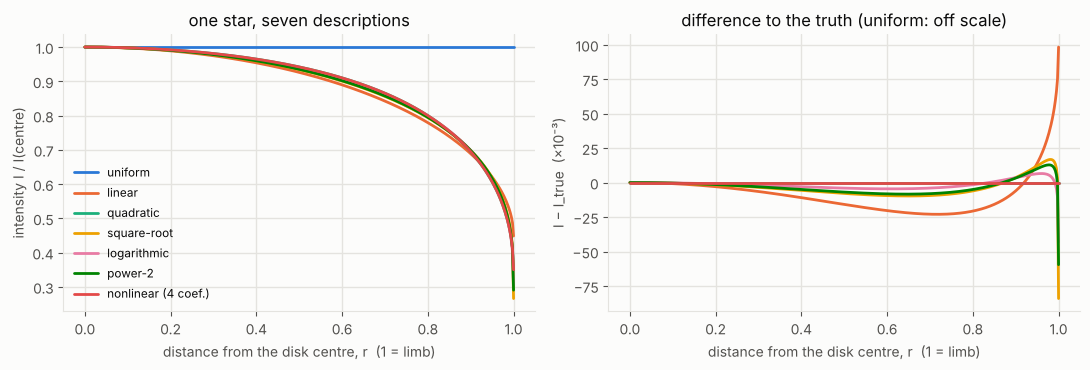

In [2]:
# (key, label, pizzetti name of the law, colour); the key is used everywhere below.
# "power2" has two entries: the exponent alpha fixed (section 4) or free.
SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
LAWS = [
    ("uniform",     "uniform",            "uniform",     SLOT[0]),
    ("linear",      "linear",             "linear",      SLOT[1]),
    ("quadratic",   "quadratic",          "quadratic",   SLOT[2]),
    ("squareroot",  "square-root",        "squareroot",  SLOT[3]),
    ("logarithmic", "logarithmic",        "logarithmic", SLOT[4]),
    ("power2",      "power-2 (α fixed)",  "power2",      SLOT[5]),
    ("power2_free", "power-2 (α free)",   "power2",      SLOT[6]),
    ("nonlinear",   "nonlinear (4 coef.)", "nonlinear",  SLOT[7]),
]
COLOR = {key: color for key, _, _, color in LAWS}
LABEL = {key: label for key, label, _, _ in LAWS}

def intensity(law, mu, c, alpha=None):
    """I(mu) / I(1) for n coefficient sets c (shape n x K) on a grid of mu values (m,) -> array (n, m)."""
    c = np.atleast_2d(np.asarray(c, dtype=float))
    mu = np.asarray(mu, dtype=float)
    d = 1.0 - mu[None, :]                                   # 1 - mu
    if law == "uniform":
        return np.ones((len(c), mu.size))
    if law == "linear":
        return 1.0 - c[:, :1] * d
    if law == "quadratic":
        return 1.0 - c[:, :1] * d - c[:, 1:2] * d**2
    if law == "squareroot":
        return 1.0 - c[:, :1] * d - c[:, 1:2] * (1.0 - np.sqrt(mu))[None, :]
    if law == "logarithmic":
        return 1.0 - c[:, :1] * d - c[:, 1:2] * (mu * np.log(np.where(mu > 0, mu, 1.0)))[None, :]
    if law == "power2":
        a = np.broadcast_to(np.asarray(alpha, dtype=float), (len(c),))[:, None]
        return 1.0 - c[:, :1] * (1.0 - mu[None, :] ** a)
    if law == "nonlinear":
        return 1.0 - sum(c[:, n:n + 1] * (1.0 - mu[None, :] ** ((n + 1) / 2)) for n in range(4))
    raise ValueError(law)

# the star we are going to simulate (quadratic law)
u_star = (0.40, 0.25)
r = np.linspace(0.0, 1.0, 401)                              # distance from the disk centre
mu = np.sqrt(1.0 - r**2)
I_true = intensity("quadratic", mu, [u_star])[0]

def match_truth(law):
    """Coefficients of `law` whose profile is closest to the true one (least squares, weighted by area)."""
    if law == "uniform":
        return np.array([])
    if law == "quadratic":
        return np.array(u_star)
    if law == "power2":
        f = lambda x: (intensity("power2", mu, x[None, :1], x[1])[0] - I_true) * np.sqrt(r)
        return least_squares(f, [0.6, 0.6], bounds=([0.0, 0.05], [2.0, 3.0])).x
    start = {"linear": [0.5], "squareroot": [0.3, 0.3], "logarithmic": [0.4, 0.2], "nonlinear": [0.5, 0.1, 0.1, 0.1]}[law]
    f = lambda x: (intensity(law, mu, x[None, :])[0] - I_true) * np.sqrt(r)
    return least_squares(f, start).x

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
print(f"{'law':18s} {'closest coefficients':36s} max |I - I_true|")
for key, label, law, color in LAWS:
    if key == "power2_free":
        continue
    x = match_truth(law)
    coef, alpha = (x[:1], x[1]) if law == "power2" else (x, None)
    I = intensity(law, mu, coef[None, :], alpha)[0]
    ax1.plot(r, I, color=color, label=label.replace(" (α fixed)", ""))
    if law != "uniform":
        ax2.plot(r, 1e3 * (I - I_true), color=color)
    print(f"{label:18s} {np.array2string(x, precision=3, suppress_small=True):36s} {np.abs(I - I_true).max():.1e}")
ax1.set(xlabel="distance from the disk centre, r  (1 = limb)", ylabel="intensity I / I(centre)",
        title="one star, seven descriptions")
ax1.legend(fontsize=8.5, loc="lower left")
ax2.set(xlabel="distance from the disk centre, r  (1 = limb)", ylabel="I − I_true  (×10⁻³)",
        title="difference to the truth (uniform: off scale)")
fig.tight_layout();

**What the figure shows**

- Apart from the uniform disk, the laws are good descriptions of this star. They differ by at most a few percent of the intensity over most of the disk, and by up to about 0.1 right at the
  limb, in the **outer part of the disk** where the intensity drops steeply (note the right panel).
- The simplest limb-darkening law, the **linear** law, has the largest mismatch: with a single coefficient it cannot bend the profile as sharply
  as the true one near the limb (the intensity there is about 0.1 too high).
- The laws are *nested*: uniform is the linear law with u₁ = 0, and linear is the quadratic law with u₂ = 0. The four-coefficient
  nonlinear law contains the quadratic law as a special case, with c = (0, u₁ + 2u₂, 0, −u₂) = (0, 0.9, 0, −0.25), which is
  exactly what the least-squares search above found (the first and third coefficient are zero up to rounding, the match is perfect).
  More coefficients mean more flexibility. As we will see, flexibility is not free: the data have to determine every extra coefficient.

## 2. The data

We reuse the simulated hot Jupiter of notebooks 02 and 03: seven transits observed at a 2-minute cadence with 500 ppm of white noise
(`sigma`). The *true* limb darkening is quadratic with u₁ = 0.40, u₂ = 0.25. Because the data are simulated we know the right
answer (`truth`), so we can tell which fits recover it. With real data you would have to judge by other means (section 7).

`make_params` fills a `TransitParams` object, which holds the planet and star parameters in the same way as in batman. We will
call it again and again below with different laws. The impact parameter is *b* = *a* cos *i*, in units of the stellar radius.

1316 data points, 7 transits


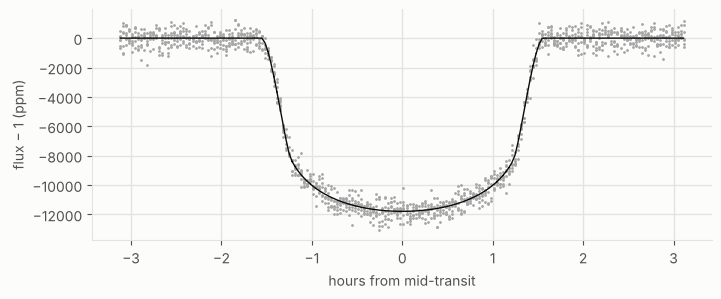

In [3]:
truth = dict(t0=0.0, per=3.5, rp=0.10, a=9.0, b=0.35, u1=u_star[0], u2=u_star[1])
sigma = 500e-6                                              # white noise per point (flux units)

def make_params(law, u):
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = truth["t0"], truth["per"], truth["rp"], truth["a"]
    p.inc = np.degrees(np.arccos(truth["b"] / truth["a"]))
    p.ecc, p.w = 0.0, 90.0                                  # circular orbit
    p.limb_dark, p.u = law, list(u)
    return p

epochs = np.arange(7)                                       # 7 transits
t_one = np.arange(-0.13, 0.13, 2.0 / 1440)                  # +-0.13 d around each mid-transit, 2-min cadence
t = (truth["t0"] + epochs[:, None] * truth["per"] + t_one[None, :]).ravel()

p_true = make_params("quadratic", [truth["u1"], truth["u2"]])
f_true = pizzetti.TransitModel(p_true, t, series_tol=0.0, limb="quadrature").light_curve(p_true)
y = f_true + sigma * np.random.default_rng(42).standard_normal(t.size)

fold = (t - truth["t0"] + 0.5 * truth["per"]) % truth["per"] - 0.5 * truth["per"]    # phase-folded time
plt.figure(figsize=(8, 3))
plt.plot(24 * fold, 1e6 * (y - 1), ".", ms=2, color="0.65")
plt.plot(24 * np.sort(fold), 1e6 * (f_true[np.argsort(fold)] - 1), color=INK, lw=1)
plt.xlabel("hours from mid-transit"); plt.ylabel("flux − 1 (ppm)")
print(f"{t.size} data points, {epochs.size} transits")

## 3. Fitting with one law, step by step

We start with the quadratic law, the one that generated the data. The class is `MarginalTransitModel`. Its arguments:

- `params`: a `TransitParams` object. Parameters we do not sample (here the eccentricity and the argument of periastron) are used as given;
  sampled ones only provide starting values. **`limb_dark` selects the law.** The limb-darkening coefficients in `params.u` are *ignored*,
  because they are free parameters, integrated out as described below. (Only for `"power2"`, `u[1]` is the exponent α, see section 4.)
- `t, y, sigma`: the times, fluxes and flux uncertainties.
- `free`: the parameters we want to sample: mid-transit time `t0`, period `per`, radius ratio `rp`, scaled orbital distance `a`, and impact parameter `b`.
- `bounds`: ranges of flat (uniform) priors. Unlisted parameters get wide default ranges.

What is special about this model: the limb-darkening coefficients **and** the out-of-transit flux level `f0` are not sampled.
For a fixed geometry the light curve is a *linear* function of them, so they can be integrated out analytically, over the region where the
star's intensity profile is physical (positive everywhere and not brighter towards the limb). The sampler explores only the 5-dimensional
geometry; the coefficients are drawn afterwards, once for each geometry sample, from their exact conditional distribution.
You do not have to choose priors or starting values for the coefficients.

`fit()` then produces the posterior in one call. It finds the maximum of the posterior, builds a proposal distribution around it,
and corrects with **importance sampling** (no MCMC chain to monitor). Arguments: `n` is the number of draws, `seed` makes the run reproducible, and `ld="u"`
asks for the usual coefficients u₁, u₂ of the law. (The default for the quadratic law is Kipping's q₁, q₂, which are convenient for sampling.)

In [4]:
GEOM = ["t0", "per", "rp", "a", "b"]                         # the geometry parameters we sample

p = make_params("quadratic", [0.4, 0.25])                    # p.u is ignored by MarginalTransitModel
model = pizzetti.MarginalTransitModel(p, t, y, sigma, free=GEOM,
                                      bounds={"rp": (0, 0.5), "a": (1.5, 100)})

model.fit(seed=0, n=100)                                     # warm-up: the first call compiles code (a few seconds, once)
t_start = time.perf_counter()
result = model.fit(seed=1, n=8000, ld="u")
wall = time.perf_counter() - t_start

d = result.diagnostics
print(f"fit() took {wall:.1f} s")
print(f"method = {d['method']},  khat = {d['khat']:.2f},  effective sample size = {d['ess_total']:.0f} of {len(result.samples)},  "
      f"likelihood evaluations = {d['n_eval']}")

fit() took 2.0 s
method = profile-IS,  khat = -0.21,  effective sample size = 5884 of 8000,  likelihood evaluations = 22847


**Reading the diagnostics**

- `method`: `profile-IS` means importance sampling worked. If its checks fail, `fit()` falls back to emcee automatically and says so here (`emcee (fallback)`).
- `khat` (k̂): how heavy-tailed the importance weights are. Below 0.5 is good, 0.5–0.7 is acceptable, and at 0.7 or more `fit()` does not trust the result.
- `ess_total`: the **effective sample size**, the number of independent draws that the 8000 weighted draws are worth.
- `n_eval`: how often the likelihood was evaluated (the cost of the fit).

The result object holds the posterior: `result.labels` names the columns, `result.samples` has equal-weight draws, and
`result.weighted_samples` with `result.weights` are the exact weighted draws (better for histograms and corner plots).
Besides the five geometry parameters you get the law's coefficients and the baseline flux `f0`, all drawn from the posterior.

In [5]:
print(result.labels)
print(result.samples.shape, "<- (draws, columns)\n")
print(result.summary())                                      # median and 1-sigma (16-84 %) interval of every column
print("\ntruth:", {k: v for k, v in truth.items()})

['t0', 'per', 'rp', 'a', 'b', 'u1', 'u2', 'f0']
(8000, 8) <- (draws, columns)

              median     -1sigma     +1sigma
t0      -0.000144257    0.000116    0.000116
per         3.500054    3.23e-05     3.1e-05
rp        0.09964358    0.000739    0.000642
a           9.169479        0.14       0.155
b           0.299614      0.0681      0.0476
u1         0.4333344       0.043      0.0455
u2         0.1957036      0.0926      0.0943
f0         0.9999852    1.89e-05    1.87e-05

truth: {'t0': 0.0, 'per': 3.5, 'rp': 0.1, 'a': 9.0, 'b': 0.35, 'u1': 0.4, 'u2': 0.25}


## 4. Changing the law is a one-line change

To fit with another law we only change `limb_dark` in the `TransitParams`. Everything else stays the same. Two details:

- **power-2** (I = 1 − c (1−μ<sup>α</sup>)) has an exponent α. `fit()` keeps it fixed at `params.u[1]` unless `"alpha"` is added to `free`; then it is
  sampled like the geometry. We run both variants. In the output, the power-2 coefficient *c* is labelled `u1` and the exponent `alpha`.
  We restrict α to the range 0.1–3 (this covers stellar atmospheres; pizzetti itself accepts any α > 0).
- The coefficients that `fit()` returns follow each law's usual convention (we asked for `ld="u"`), so they are only comparable within one law.

The loop below fits all remaining variants and prints the diagnostics. The numbers in `SETUP` (starting values for `params.u`)
are irrelevant, except for the power-2 exponent 0.6.

In [6]:
ALPHA_FIXED = 0.6
SETUP = {   # key: (values for params.u, extra free parameters, number of limb-darkening coefficients)
    "uniform":     ([],                   [],        0),
    "linear":      ([0.5],                [],        1),
    "quadratic":   ([0.4, 0.25],          [],        2),
    "squareroot":  ([0.3, 0.3],           [],        2),
    "logarithmic": ([0.4, 0.2],           [],        2),
    "power2":      ([0.6, ALPHA_FIXED],   [],        1),
    "power2_free": ([0.6, ALPHA_FIXED],   ["alpha"], 2),
    "nonlinear":   ([0.5, 0.1, 0.1, 0.1], [],        4),
}

results = {"quadratic": dict(result=result, wall=wall)}      # the fit of section 3 is reused
for key, label, law, color in LAWS:
    if key in results:
        continue
    u, extra, _ = SETUP[key]
    bounds = {"rp": (0, 0.5), "a": (1.5, 100)}
    if extra:
        bounds["alpha"] = (0.1, 3.0)
    m = pizzetti.MarginalTransitModel(make_params(law, u), t, y, sigma, free=GEOM + extra, bounds=bounds)
    t1 = time.perf_counter()
    res = m.fit(seed=1, n=8000, ld="u")
    results[key] = dict(result=res, wall=time.perf_counter() - t1)

print(f"{'law':20s} {'coef.':>5s} {'method':>11s} {'khat':>6s} {'ESS':>6s} {'evaluations':>12s} {'time [s]':>9s}")
for key, label, law, color in LAWS:
    d, w = results[key]["result"].diagnostics, results[key]["wall"]
    print(f"{label:20s} {SETUP[key][2]:5d} {d['method']:>11s} {d['khat']:6.2f} {d['ess_total']:6.0f} {d['n_eval']:12d} {w:9.1f}")

/home/claude/pizzetti/src/pizzetti/_marginal.py:776: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'A', False, aligned=True), Array(float64, 1, 'C', False, aligned=True))
  okc, c, Fi, ld_, ch_ = _ne_solve(A, yw)


law                  coef.      method   khat    ESS  evaluations  time [s]
uniform                  0  profile-IS   0.20   5870        20702      24.3
linear                   1  profile-IS  -0.24   5871        23549       1.2
quadratic                2  profile-IS  -0.21   5884        22847       2.0
square-root              2  profile-IS   0.28   5450        22163       6.9
logarithmic              2  profile-IS  -0.08   5767        21329       2.9
power-2 (α fixed)        1  profile-IS  -0.13   5874        23160       1.7
power-2 (α free)         2  profile-IS  -0.04   5554        36100       8.9
nonlinear (4 coef.)      4  profile-IS   0.37   5634        22866      18.2


**What to look at in this table**

- All eight fits worked with importance sampling (`profile-IS`): k̂ is 0.37 at most (below the 0.5 mark for "good") and the effective sample size is
  at least 5400 of 8000 draws, so no emcee fallback was needed and we can treat the draws as a faithful sample of the posterior.
- The number of likelihood evaluations is similar for all laws (about 21 000 to 36 000). Free α, the one law with an extra sampled
  parameter, needs the most.
- The run times differ because laws with non-integer powers of μ (square-root, logarithmic, power-2, nonlinear) cost more per evaluation than
  uniform, linear and quadratic, and because the nonlinear law has to check a curved physical region for its four coefficients.
  The first fit with a new kind of law also builds some tables once per session (the first square-root fit is slower than a second one would be).
  Times are those of the machine that ran this notebook.

## 5. Comparing the geometry

The planet's radius ratio, the orbital distance and the impact parameter are what we usually want to know. The figure shows, for each
law, the posterior median and the 68 % interval of R<sub>p</sub>/R<sub>⋆</sub>, a/R<sub>⋆</sub> and *b*. The grey vertical line is the truth. Look for two things:

1. **Accuracy:** does the interval contain the truth?
2. **Precision:** how wide is the interval? (A narrow interval is only good if it is also accurate.)

The table gives the offset from the truth in units of the interval's half-width, `z = (median − truth) / σ`.
|z| ≲ 2 is an acceptable fit. A uniform-disk result that is off the plot's range is marked with an arrow.

                                            rp                         a                         b
uniform                 0.1060 ± 0.0001  z= +40.3      7.03 ± 0.06  z= -35.7      0.73 ± 0.01  z= +70.9
linear                  0.1006 ± 0.0004  z=  +1.5      9.06 ± 0.11  z=  +0.5      0.35 ± 0.03  z=  +0.0
quadratic               0.0996 ± 0.0007  z=  -0.5      9.17 ± 0.15  z=  +1.1      0.30 ± 0.06  z=  -0.9
square-root             0.0996 ± 0.0006  z=  -0.7      9.15 ± 0.14  z=  +1.1      0.30 ± 0.05  z=  -0.9
logarithmic             0.0994 ± 0.0008  z=  -0.8      9.18 ± 0.16  z=  +1.2      0.29 ± 0.07  z=  -0.9
power-2 (α fixed)       0.0995 ± 0.0005  z=  -1.0      9.16 ± 0.13  z=  +1.2      0.30 ± 0.05  z=  -1.0
power-2 (α free)        0.0996 ± 0.0006  z=  -0.6      9.14 ± 0.13  z=  +1.0      0.31 ± 0.05  z=  -0.9
nonlinear (4 coef.)     0.1000 ± 0.0007  z=  -0.0      9.14 ± 0.14  z=  +1.0      0.32 ± 0.05  z=  -0.6
truth                   0.1000                      9.00             

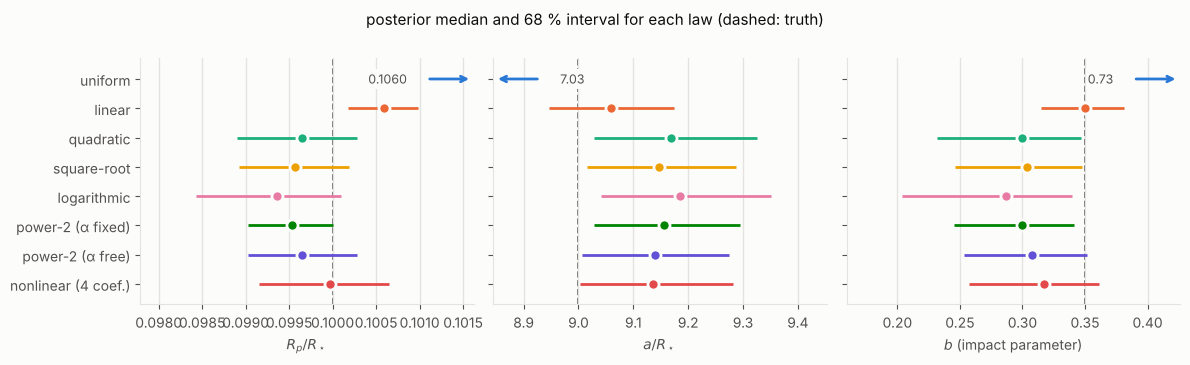

In [7]:
def col(res, name):
    return res.samples[:, res.labels.index(name)]

def interval(x):
    lo, med, hi = np.percentile(x, [16, 50, 84])
    return med, med - lo, hi - med                           # median, minus error, plus error

pars = [("rp", r"$R_p/R_\star$", ".4f"), ("a", r"$a/R_\star$", ".2f"), ("b", r"$b$ (impact parameter)", ".2f")]
print(f"{'':20s}" + "".join(f"{name:>26s}" for name, _, _ in pars))
for key, label, law, color in LAWS:
    row = f"{label:20s}"
    for name, _, fmt in pars:
        med, em, ep = interval(col(results[key]["result"], name))
        z = (med - truth[name]) / (0.5 * (em + ep))
        row += f"{med:{'10' + fmt}} ± {0.5 * (em + ep):{'.' + fmt[1:]}}  z={z:+6.1f}"
    print(row)
print(f"{'truth':20s}" + "".join(f"{truth[name]:{'10' + fmt}}{'':16s}" for name, _, fmt in pars))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
ypos = {key: -i for i, (key, *_rest) in enumerate(LAWS)}
for ax, (name, xlabel, fmt) in zip(axes, pars):
    iv = {key: interval(col(results[key]["result"], name)) for key, *_rest in LAWS}
    ref = [v for k, v in iv.items() if k != "uniform"]       # axis range from all laws except the uniform disk
    lo = min(m - e for m, e, _ in ref + [(truth[name], 0, 0)])
    hi = max(m + e for m, _, e in ref + [(truth[name], 0, 0)])
    pad = 0.25 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.axvline(truth[name], color=INK2, lw=1.2, ls="--", zorder=1)
    for key, (med, em, ep) in iv.items():
        if lo - pad <= med <= hi + pad:
            ax.errorbar(med, ypos[key], xerr=[[em], [ep]], fmt="o", color=COLOR[key], ms=8, mec=SURFACE, mew=2,
                        elinewidth=2, capsize=0, zorder=3)
        else:                                                # off the scale: mark with an arrow and the value
            side = 1 if med > hi else -1
            ax.annotate(f"{med:{fmt}}", xy=(0.80 if side > 0 else 0.20, ypos[key]), xycoords=("axes fraction", "data"),
                        ha="right" if side > 0 else "left", va="center", fontsize=9, color=INK2,
                        bbox=dict(fc=SURFACE, ec="none", pad=1.5))
            ax.annotate("", xy=(0.995 if side > 0 else 0.005, ypos[key]), xytext=(0.86 if side > 0 else 0.14, ypos[key]),
                        xycoords=("axes fraction", "data"), textcoords=("axes fraction", "data"),
                        arrowprops=dict(arrowstyle="->", color=COLOR[key], lw=2))
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(list(ypos.values()), [LABEL[k] for k in ypos])
axes[0].set_ylim(min(ypos.values()) - 0.7, 0.7)
fig.suptitle("posterior median and 68 % interval for each law (dashed: truth)", y=1.0, fontsize=11)
fig.tight_layout();

**What the geometry tells us**

- **The uniform disk is confidently wrong.** Its intervals are tiny, but they are far from the truth: R<sub>p</sub>/R<sub>⋆</sub> is too large by 6 %,
  a/R<sub>⋆</sub> is 7.0 instead of 9.0, and the impact parameter comes out as 0.73 instead of 0.35 (z = +40, −36 and +71). Without limb darkening the model can only
  imitate the rounded bottom of the transit by changing the geometry. This is the pitfall of this notebook: **a wrong law does not announce
  itself in the error bars.**
- **All seven laws with limb darkening recover the truth.** R<sub>p</sub>/R<sub>⋆</sub>, a/R<sub>⋆</sub> and *b* are within 1.5 σ of the true values for every one of them.
  The geometry is not very sensitive to *which* reasonable law we use, as long as the law has some freedom.
- **The widths differ.** The one-coefficient laws (linear, and power-2 with fixed α) give the narrowest intervals for R<sub>p</sub>/R<sub>⋆</sub> (± 0.0004 and ± 0.0005),
  the two-coefficient laws are wider (± 0.0006 to ± 0.0008). The extra freedom has to be paid for with larger uncertainty, because the data must
  determine the additional coefficients too. A narrow interval is only trustworthy when the law is flexible enough, though: the linear
  law has the largest offset of the seven (R<sub>p</sub>/R<sub>⋆</sub> is 1.4 σ too high), and "power-2 (α fixed)" is narrow because we *told* it that α = 0.6.
  Freeing α widens the interval, and the data say α = 0.61 (+0.18 / −0.11), so our guess was lucky.

## 6. Comparing the limb darkening itself

The coefficients of different laws mean different things (u₁ of the linear law is not u₁ of the quadratic law), so we cannot compare
them one by one. Here they are for completeness, with 68 % intervals and, where a law has several coefficients, the strongest
correlation between two of them:

In [8]:
for key, label, law, color in LAWS:
    res = results[key]["result"]
    names = [l for l in res.labels if l.startswith("u") or l == "alpha"]
    parts = []
    for nme in names:
        med, em, ep = interval(col(res, nme))
        parts.append(f"{nme} = {med:.2f} (+{ep:.2f} / −{em:.2f})")
    line = f"{label:20s} " + (",  ".join(parts) if parts else "(no limb-darkening coefficients)")
    if len(names) > 1:                                       # strongest correlation between two coefficients
        cc = np.corrcoef(np.array([col(res, nme) for nme in names]))
        line += f"   [largest |correlation| {np.abs(cc - np.eye(len(names))).max():.2f}]"
    print(line)

uniform              (no limb-darkening coefficients)
linear               u1 = 0.53 (+0.01 / −0.01)
quadratic            u1 = 0.43 (+0.05 / −0.04),  u2 = 0.20 (+0.09 / −0.09)   [largest |correlation| 0.95]
square-root          u1 = 0.11 (+0.19 / −0.15),  u2 = 0.72 (+0.26 / −0.32)   [largest |correlation| 1.00]
logarithmic          u1 = 0.73 (+0.11 / −0.09),  u2 = 0.28 (+0.14 / −0.13)   [largest |correlation| 0.99]
power-2 (α fixed)    u1 = 0.78 (+0.02 / −0.02)
power-2 (α free)     alpha = 0.61 (+0.18 / −0.11),  u1 = 0.77 (+0.15 / −0.14)   [largest |correlation| 0.96]
nonlinear (4 coef.)  u1 = 1.37 (+1.37 / −0.94),  u2 = -2.85 (+3.09 / −4.38),  u3 = 3.93 (+5.14 / −3.87),  u4 = -1.68 (+1.61 / −2.05)   [largest |correlation| 1.00]


**What the coefficients tell us**

- The coefficients of different laws cannot be compared: the same star is u₁ = 0.43 in the quadratic law, u₁ = 0.53 in the linear law and c = 0.78 in the power-2 law.
- Flexible laws have **poorly determined individual coefficients**. The square-root law has u₁ = 0.11 (+0.18 / −0.15) and the nonlinear law has coefficients
  such as u₂ = −2.8 (+3.1 / −4.4), with alternating signs. This does not mean that the fit failed. The coefficients of a law are strongly
  correlated (see the last column above), and the data constrain *combinations* of them (they constrain the shape of the profile) rather than each one.
  **Do not interpret individual coefficients of flexible laws; look at the profile they describe.**

The next figure turns every posterior sample into its intensity profile *I*(*r*). It shows the median and the 68 % band of the profiles,
for each law, against the true profile (dashed).

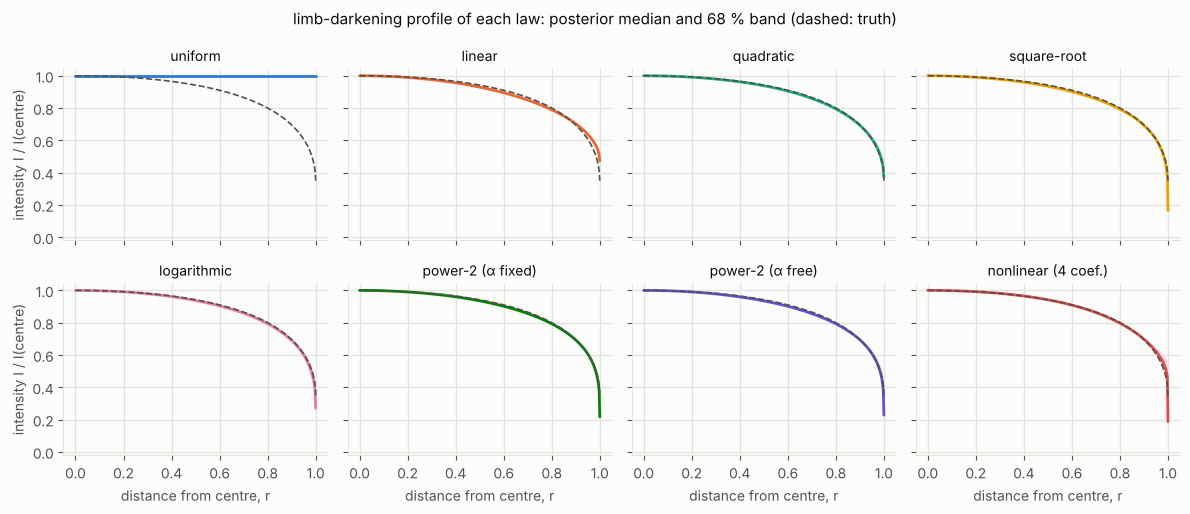

In [9]:
def profile_bands(key, n=1500, seed=0):
    """Draw n posterior samples, turn each into an intensity profile I(r); return 16/50/84 % curves."""
    res, law = results[key]["result"], dict((k, l) for k, _, l, _ in LAWS)[key]
    S = res.samples[np.random.default_rng(seed).choice(len(res.samples), n, replace=False)]
    ucols = [res.labels.index(l) for l in res.labels if l.startswith("u")]
    alpha = S[:, res.labels.index("alpha")] if "alpha" in res.labels else ALPHA_FIXED
    I = intensity(law, mu, S[:, ucols], alpha)               # shape (n, len(r))
    return np.percentile(I, [16, 50, 84], axis=0)

bands = {key: profile_bands(key) for key, *_rest in LAWS}

fig, axes = plt.subplots(2, 4, figsize=(12, 5.2), sharex=True, sharey=True)
for ax, (key, label, law, color) in zip(axes.ravel(), LAWS):
    lo, med, hi = bands[key]
    ax.fill_between(r, lo, hi, color=color, alpha=0.18, lw=0)
    ax.plot(r, med, color=color)
    ax.plot(r, I_true, color=INK2, lw=1.2, ls="--")
    ax.set_title(label, fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("distance from centre, r")
for ax in axes[:, 0]:
    ax.set_ylabel("intensity I / I(centre)")
axes[0, 0].set_ylim(-0.02, 1.04)
fig.suptitle("limb-darkening profile of each law: posterior median and 68 % band (dashed: truth)", fontsize=11)
fig.tight_layout();

intensity I(r) / I(0)              r = 0.5             r = 0.9            r = 0.99
uniform                  1.000 ± 0.000      1.000 ± 0.000      1.000 ± 0.000   
linear                   0.929 ± 0.002      0.703 ± 0.007      0.547 ± 0.011   
quadratic                0.938 ± 0.004      0.693 ± 0.010      0.485 ± 0.035   
square-root              0.935 ± 0.003      0.693 ± 0.009      0.453 ± 0.039   
logarithmic              0.937 ± 0.004      0.690 ± 0.012      0.453 ± 0.051   
power-2 (α fixed)        0.935 ± 0.002      0.693 ± 0.008      0.458 ± 0.014   
power-2 (α free)         0.935 ± 0.003      0.694 ± 0.009      0.463 ± 0.041   
nonlinear (4 coef.)      0.942 ± 0.007      0.698 ± 0.011      0.515 ± 0.071   
truth                    0.942                 0.695                 0.472              


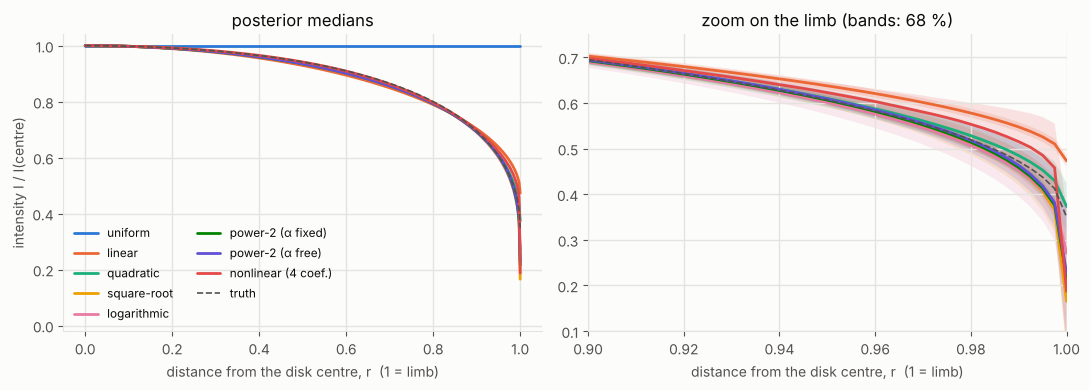

In [10]:
# the posterior medians of all laws in one panel; right: zoom on the limb with the 68 % bands
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ax in (ax1, ax2):
    for key, label, law, color in LAWS:
        if ax is ax2 and key != "uniform":
            ax.fill_between(r, bands[key][0], bands[key][2], color=color, alpha=0.15, lw=0)
        ax.plot(r, bands[key][1], color=color, label=label)
    ax.plot(r, I_true, color=INK2, lw=1.2, ls="--", label="truth")
    ax.set_xlabel("distance from the disk centre, r  (1 = limb)")
ax1.set(ylabel="intensity I / I(centre)", ylim=(-0.02, 1.04), title="posterior medians")
ax1.legend(fontsize=8.5, loc="lower left", ncol=2)
ax2.set(xlim=(0.9, 1.0), ylim=(0.1, 0.75), title="zoom on the limb (bands: 68 %)")
fig.tight_layout()

radii = [0.5, 0.9, 0.99]
idx = [int(np.argmin(np.abs(r - x))) for x in radii]
print(f"{'intensity I(r) / I(0)':22s}" + "".join(f"{'r = ' + str(x):>20s}" for x in radii))
for key, label, law, color in LAWS:
    lo, med, hi = bands[key]
    print(f"{label:22s}" + "".join(f"{med[i]:8.3f} ± {0.5 * (hi[i] - lo[i]):.3f}   " for i in idx))
print(f"{'truth':22s}" + "".join(f"{I_true[i]:8.3f}{'':14s}" for i in idx))

**What the profiles tell us**

- Except for the uniform disk, every law follows the true profile closely over most of the disk. At *r* = 0.5 the intensity is known to better
  than 1 % for all laws, and at *r* = 0.9 to 1–2 %.
- The data constrain the limb least. The ingress and egress are short, and the intensity changes quickly with *r*. At *r* = 0.99 the bands are widest (± 0.04 for
  the quadratic law and ± 0.07 for the nonlinear law). Here the laws also *extrapolate* differently towards the very edge (see the zoom).
- The linear law is too bright at the limb: 0.55 ± 0.01 where the truth is 0.47, an offset of about 7σ. It is the clearest sign that this law is too simple for
  this star. It hardly harms the geometry here, but it is a warning that the narrow linear-law intervals of the previous section are
  too optimistic.

## 7. Does the law fit the data?

Real data come without a truth line, so the practical test is: *does the fitted model describe the data?* For each law we take 100 random
posterior samples, compute their model light curves, and look at the **residuals** (data minus model). The residuals of a good fit look like
white noise. A visible pattern (for example a bump during the transit) means the model is missing something. We also compute χ², the sum
of squared residuals in units of the noise; for a good fit χ² ≈ N, the number of data points.

(`pizzetti.TransitModel` has no logarithmic law, so here we use batman for *all* laws to draw the model curves. batman accepts the same
names and coefficients. This step is only for plotting.)

N = 1316 data points; chi^2 of a typical posterior sample (a good fit has chi^2 = N within +-51).
The noise added to this data set has 43 ppm rms in the 15-minute bins (white noise typically gives 69 ppm; this realisation is on the quiet side). A perfect model would leave exactly that.

law                  coef.    chi^2  chi^2 - N  chi^2 - chi^2(quad.)  rms of bins [ppm]
uniform                  0   2198.4      882.4                 898.5                298
linear                   1   1302.6      -13.4                   2.7                 45
quadratic                2   1299.9      -16.1                   0.0                 38
square-root              2   1298.6      -17.4                  -1.3                 39
logarithmic              2   1299.6      -16.4                  -0.3                 39
power-2 (α fixed)        1   1298.9      -17.1                  -1.0                 39
power-2 (α free)         2   1300.3      -15.7                   0.4                 39
nonlinea

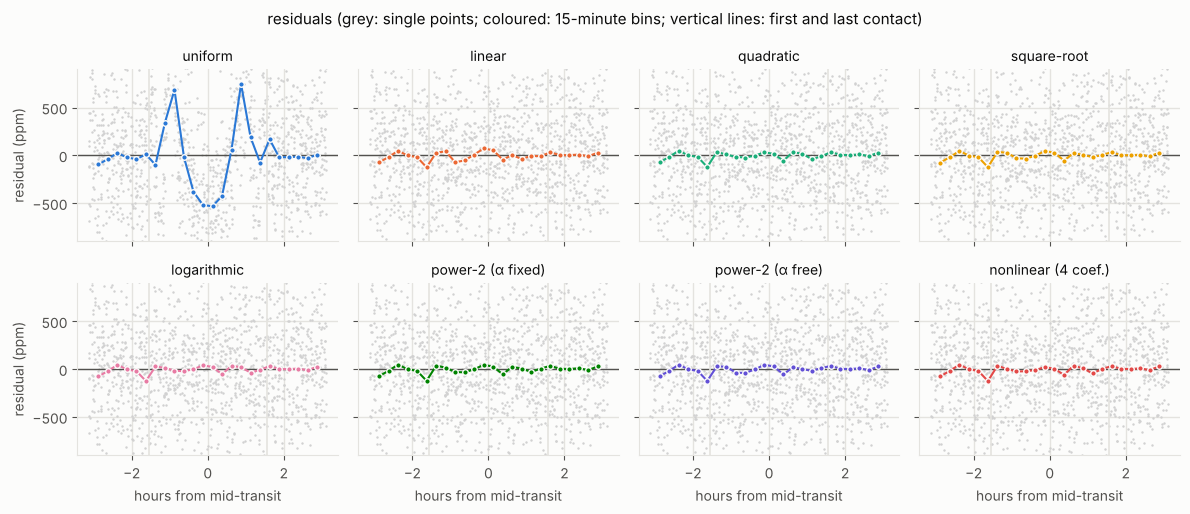

In [11]:
def curves(key, n=100, seed=0):
    """Model light curves (including the fitted baseline f0) for n random posterior samples."""
    res, law = results[key]["result"], dict((k, l) for k, _, l, _ in LAWS)[key]
    S = res.samples[np.random.default_rng(seed).choice(len(res.samples), n, replace=False)]
    pb, bm, out = batman.TransitParams(), None, []
    pb.ecc, pb.w, pb.limb_dark = 0.0, 90.0, law
    for row in S:
        g = dict(zip(res.labels, row))
        pb.t0, pb.per, pb.rp, pb.a = g["t0"], g["per"], g["rp"], g["a"]
        pb.inc = np.degrees(np.arccos(g["b"] / g["a"]))
        if law == "power2":
            pb.u = [g["u1"], g.get("alpha", ALPHA_FIXED)]
        else:
            pb.u = [g[l] for l in res.labels if l.startswith("u")]
        if bm is None:
            bm = batman.TransitModel(pb, t)
        out.append(g["f0"] * bm.light_curve(pb))
    return np.array(out)

# time window of the transit (circular orbit), to mark ingress and egress
inc = np.arccos(truth["b"] / truth["a"])
T14 = truth["per"] / np.pi * np.arcsin(np.sqrt((1 + truth["rp"])**2 - truth["b"]**2) / (truth["a"] * np.sin(inc)))

edges = np.arange(-3.0, 3.01, 0.25)                         # 15-minute bins (hours)
centres = 0.5 * (edges[1:] + edges[:-1])
fold_h = 24 * fold
which = np.digitize(fold_h, edges) - 1
counts = np.bincount(which[(which >= 0) & (which < len(centres))], minlength=len(centres))
noise_rms = 1e6 * sigma / np.sqrt(counts.mean())            # typical rms of a 15-minute bin of pure white noise
injected = 1e6 * (y - f_true)                                # the noise that was actually added to this data set
injected_rms = np.sqrt(np.mean([injected[which == i].mean()**2 for i in range(len(centres))]))

info = {}
for key, label, law, color in LAWS:
    C = curves(key)
    resid = 1e6 * (y - C.mean(axis=0))                       # residual of the mean model, in ppm
    binned = np.array([resid[which == i].mean() for i in range(len(centres))])
    info[key] = dict(chi2=np.median(np.sum(((y - C) / sigma)**2, axis=1)), resid=resid, binned=binned)

ymax = 100 * np.ceil(1.1 * np.abs(info["uniform"]["binned"]).max() / 100)
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2), sharex=True, sharey=True)
for ax, (key, label, law, color) in zip(axes.ravel(), LAWS):
    ax.plot(fold_h, info[key]["resid"], ".", ms=1.5, color="0.82", rasterized=True)
    ax.axhline(0, color=INK2, lw=1)
    for edge in (-12 * T14, 12 * T14):
        ax.axvline(edge, color=GRID, lw=1.2)
    ax.plot(centres, info[key]["binned"], "o-", color=color, ms=4, lw=1.5, mec=SURFACE, mew=1)
    ax.set_title(label, fontsize=10)
axes[0, 0].set_ylim(-ymax, ymax)
for ax in axes[1]:
    ax.set_xlabel("hours from mid-transit")
for ax in axes[:, 0]:
    ax.set_ylabel("residual (ppm)")
fig.suptitle("residuals (grey: single points; coloured: 15-minute bins; vertical lines: first and last contact)", fontsize=11)
fig.tight_layout()

N = len(y)
print(f"N = {N} data points; chi^2 of a typical posterior sample (a good fit has chi^2 = N within +-{np.sqrt(2 * N):.0f}).")
print(f"The noise added to this data set has {injected_rms:.0f} ppm rms in the 15-minute bins (white noise typically gives "
      f"{noise_rms:.0f} ppm; this realisation is on the quiet side). A perfect model would leave exactly that.\n")
print(f"{'law':20s} {'coef.':>5s} {'chi^2':>8s} {'chi^2 - N':>10s} {'chi^2 - chi^2(quad.)':>21s} {'rms of bins [ppm]':>18s}")
for key, label, law, color in LAWS:
    c2 = info[key]["chi2"]
    print(f"{label:20s} {SETUP[key][2]:5d} {c2:8.1f} {c2 - N:10.1f} {c2 - info['quadratic']['chi2']:21.1f} "
          f"{np.sqrt(np.mean(info[key]['binned']**2)):18.0f}")

**What the residuals tell us**

- The **uniform disk leaves a large pattern** in the residuals: bumps of several hundred ppm, a dip of about −500 ppm at mid-transit, and
  χ² = N + 880. The data contain information that this model cannot fit.
- **All other laws look alike.** Their binned residuals scatter around zero at the level of the noise that we added to the simulated data
  (a perfect model would leave exactly that noise; this particular realisation happens to be on the quiet side when binned), and χ² is within the
  expected ±51 of N. The laws differ by at most a few units of χ² (even the linear law, whose limb intensity is 7σ off, costs only Δχ² ≈ 3).
- So residuals and χ² reveal **gross** failures (the uniform disk) but cannot choose between the seven acceptable laws: 7 transits at 500 ppm are not enough to tell them apart.
  This is a common situation. The practical consequence is that the result should not depend on the choice, which brings us to the summary.

## 8. Summary and advice

**What we found** (simulated hot Jupiter, quadratic truth, 7 transits, 500 ppm):

1. A law that is too simple can give a *confidently wrong* result. The uniform disk ignores limb darkening and returned R<sub>p</sub>/R<sub>⋆</sub>, a/R<sub>⋆</sub> and *b* tens of σ off, with tiny error bars.
   Its residuals showed the problem clearly.
2. Any law with a free coefficient or two recovered the geometry. The one-coefficient laws gave the narrowest intervals (with the caveat of section 5).
3. Highly flexible laws (here the four-coefficient nonlinear law) were slower, had coefficients that are individually meaningless, and gave no better fit than the simpler
   laws. They only help when the data are good enough to constrain the extra freedom.
4. The best-fitting profiles of all laws agree closely over most of the disk and differ at the limb. That is where the data say least.
5. With this much data, residuals and χ² do not discriminate between the acceptable laws.

**Practical advice**

- A two-coefficient law (quadratic, square-root, or power-2 with free α) is a good default. For an important result, **repeat the fit with a second law** as a robustness check. If the geometry agrees (as here),
  your conclusions do not depend on the law.
- Check `result.diagnostics` for every fit (method, k̂ and the effective sample size), and look at the residuals.
- Be careful with laws that have fixed coefficients: they give narrow intervals only if the fixed values are right.
- If you know something about the star (from model atmospheres, say), put it in as a prior with the `ld_prior` argument of `MarginalTransitModel`.
  A Gaussian prior on (u₁, u₂) is exact for the quadratic law, and any law accepts a callable. See [notebook 06](06_marginal_transit_model.ipynb).
- Remember that this is a single noise realisation. Fits to real data can behave differently. For example, a low signal-to-noise light curve has wider bands everywhere, and then even
  the uniform disk may look acceptable (but be biased).

**Try it yourself**

- Change the data: generate the light curve with another law (for example `make_params("nonlinear", [0.5, 0.1, 0.1, -0.1])` for `p_true`; the dashed truth profile `I_true` needs the same change) and see which laws can still fit it.
- Change the signal-to-noise: set `sigma = 250e-6`, or use 3 instead of 7 transits (`epochs`), and see how the intervals and the residuals change.
- Compare with `ld_prior="flat"` (an argument of `MarginalTransitModel(...)`), which removes the physical constraint on the coefficients.
- Compare the results with an MCMC run: `method="emcee"` in `model.fit(...)`, or the emcee sampler of [notebook 06](06_marginal_transit_model.ipynb).

## What you learned

- A limb-darkening law is a model of I(μ); changing it is a one-line change of `limb_dark`.
- A law that is too simple (the uniform disk) can give confidently wrong geometry; residuals and χ² reveal it.
- Flexible laws constrain the *profile*, not their individual coefficients; compare profiles, not coefficients.
- Read `result.diagnostics` (method, k̂, effective sample size) for every fit.

**Next:** [06 · Fitting with limb darkening integrated out](06_marginal_transit_model.ipynb)